# PARTE 1: Montaje de Drive, descompresión del ZIP y preparación de rutas

In [ ]:
# ---------------------------------------------------------------
# Tecnológico de Monterrey
# Aprendizaje Profundo con PyTorch
#
# Autor: René de la Calleja Manzanedo
# Fecha: Mayo 2026
# Reto: Clasificación automatizada de lesiones dérmicas con deep learning.
#
# Nota. Este trabajo se limitó a usar una arquitectura de CNN dada como plantilla y era aceptable realizar modificaciones
# pequeñas y relevantes sobre ella más NO era aceptable intentar pruebas con un modelo pre-entrenado como MobileNetV2.
# ---------------------------------------------------------------

# Librerías para Ciencia de Datos
import pandas as pd
import numpy as np
import shutil
import os
import zipfile
import time
from tqdm import tqdm
from google.colab import drive
import cv2
import random

# Librerías para visualización y manejo de datos
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, precision_recall_curve

# Librerías para procesamiento y deep learning
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader, random_split, WeightedRandomSampler
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F


Montar Google Drive.

In [ ]:
drive.mount('/content/drive')
base_path = '/content/drive/My Drive/Colab Notebooks/Pytorch-course/'
zip_path = os.path.join(base_path, 'skin-cancer.zip')
extract_path = os.path.join(base_path, 'skin_cancer_extracted')

Mounted at /content/drive


Descomprimir el archivo zip y extraer imágenes.

In [ ]:
if not os.path.exists(extract_path):
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            print("✅ Descomprimiendo archivo...")
            zip_ref.extractall(extract_path)
            print("✅ Extracción completada.")
    except zipfile.BadZipFile:
        print("❌ Error: el archivo no es un ZIP válido o está dañado.")
else:
    print("ℹ️ Ya existe la carpeta descomprimida.")

ℹ️ Ya existe la carpeta descomprimida.


# PARTE 2: Cargar y preparar los datos (incluyendo metadatos)

El CSV de metadatos contiene información valiosa como:

*   image_id: ID de la imagen
*   dx: diagnóstico (melanoma, nevus, bkl, etc.)
*   age, sex, localization, etc.

De esa manera, asociamos cada imagen con sus respectivos metadatos.

In [ ]:
# Ruta al archivo CSV dentro del ZIP descomprimido
extract_path = '/content/drive/My Drive/Colab Notebooks/Pytorch-course/skin-cancer-mio/'
metadata_csv_path = os.path.join(extract_path, 'HAM10000_metadata.csv')

# Cargar el archivo
metadata = pd.read_csv(metadata_csv_path)

# Añadir columna con la ruta completa a la imagen
def build_image_path(image_id):
    folder1 = os.path.join(extract_path, 'HAM10000_images_part_1')
    folder2 = os.path.join(extract_path, 'HAM10000_images_part_2')

    filename = f"{image_id}.jpg"
    if os.path.exists(os.path.join(folder1, filename)):
        return os.path.join(folder1, filename)
    elif os.path.exists(os.path.join(folder2, filename)):
        return os.path.join(folder2, filename)
    else:
        return None  # Imagen no encontrada

metadata['image_path'] = metadata['image_id'].apply(build_image_path)

# Eliminar registros sin ruta válida
metadata = metadata[metadata['image_path'].notnull()]



Clases disponibles: ['bkl' 'nv' 'df' 'mel' 'vasc' 'bcc' 'akiec']
Cantidad por clase:
 dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


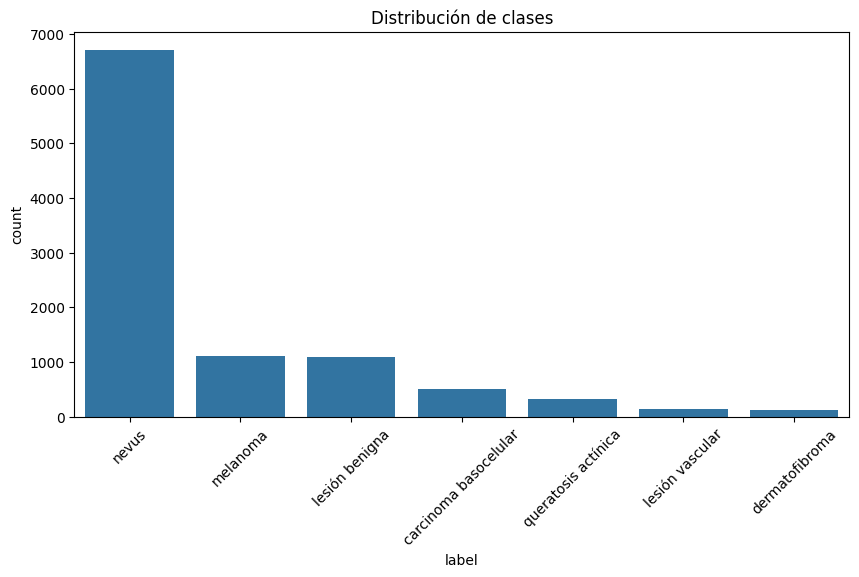

In [ ]:
# Ver clases únicas
print("Clases disponibles:", metadata['dx'].unique())
print("Cantidad por clase:\n", metadata['dx'].value_counts())

# Mapeo más legible de las clases
label_map = {
    'akiec': 'queratosis actínica',
    'bcc': 'carcinoma basocelular',
    'bkl': 'lesión benigna',
    'df': 'dermatofibroma',
    'nv': 'nevus',
    'mel': 'melanoma',
    'vasc': 'lesión vascular'
}
metadata['label'] = metadata['dx'].map(label_map)

# Codificar etiquetas (para usar con modelos)
le = LabelEncoder()
metadata['label_encoded'] = le.fit_transform(metadata['label'])

# Mostrar balance
plt.figure(figsize=(10,5))
sns.countplot(data=metadata, x='label', order=metadata['label'].value_counts().index)
plt.title("Distribución de clases")
plt.xticks(rotation=45)
plt.show()


# PARTE 3: División del dataset e implementación de DataLoaders

Objetivo:


*   Dividir el *dataset* en entrenamiento (70 %), validación (15 %) y prueba (15 %).
*   Preparar generadores de imágenes con aumentación (solo en entrenamiento).




In [ ]:
class SkinCancerDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.image_paths = dataframe['image_path'].values
        self.labels = dataframe['label_encoded'].values

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        # Cargar imagen
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")

        # Aplicar transformaciones (aumentación o normalización)
        if self.transform:
            image = self.transform(image)

        # Retornar imagen y etiqueta
        label = self.labels[idx]
        return image, label


In [ ]:
IMG_SIZE = 224

# Aumentación + normalización para entrenamiento
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    #transforms.ColorJitter(brightness=0.1, contrast=0.1), # Variación de color
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)  # [0,1] → [-1,1]
])

# Solo normalización para validación y prueba
test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])


In [ ]:
# División estratificada
train_df, temp_df = train_test_split(metadata, test_size=0.30, stratify=metadata['label_encoded'], random_state=42) # ← aquí estamos reservando el 30% para test+val
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label_encoded'], random_state=42) # ← ahora tomamos la mitad de ese 30%

# Instanciamos los datasets personalizados
train_dataset = SkinCancerDataset(train_df, transform=train_transform)
val_dataset = SkinCancerDataset(val_df, transform=test_transform)
test_dataset = SkinCancerDataset(test_df, transform=test_transform)

In [ ]:
def print_dataset_stats(df, name):
    total = len(df)
    print(f"\n📊 Conjunto: {name}")
    print(f"Total de muestras: {total}")
    print("Distribución por clase:")
    clase_counts = df['label'].value_counts()
    for clase, count in clase_counts.items():
        pct = count / total * 100
        print(f"  - {clase:25}: {count:4} muestras ({pct:.2f}%)")

# Mostrar resultados
print_dataset_stats(train_df, "Entrenamiento")
print_dataset_stats(val_df, "Validación")
print_dataset_stats(test_df, "Prueba")



📊 Conjunto: Entrenamiento
Total de muestras: 7010
Distribución por clase:
  - nevus                    : 4693 muestras (66.95%)
  - melanoma                 :  779 muestras (11.11%)
  - lesión benigna           :  769 muestras (10.97%)
  - carcinoma basocelular    :  360 muestras (5.14%)
  - queratosis actínica      :  229 muestras (3.27%)
  - lesión vascular          :   99 muestras (1.41%)
  - dermatofibroma           :   81 muestras (1.16%)

📊 Conjunto: Validación
Total de muestras: 1502
Distribución por clase:
  - nevus                    : 1006 muestras (66.98%)
  - melanoma                 :  167 muestras (11.12%)
  - lesión benigna           :  165 muestras (10.99%)
  - carcinoma basocelular    :   77 muestras (5.13%)
  - queratosis actínica      :   49 muestras (3.26%)
  - lesión vascular          :   21 muestras (1.40%)
  - dermatofibroma           :   17 muestras (1.13%)

📊 Conjunto: Prueba
Total de muestras: 1503
Distribución por clase:
  - nevus                    : 1006 m

# PARTE 4: Definición del modelo CNN

Objetivos:

*  Modelo CNN simple, pero efectivo
*  *Dropout* para combatir el sobreajuste.
*  Regularización L2 (peso de penalización en el optimizador).

In [ ]:
class SkinCancerCNN(nn.Module):
    def __init__(self, num_classes):
        super(SkinCancerCNN, self).__init__()

        # Primer bloque convolucional
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        # Segundo bloque
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        # Tercer bloque
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        # Bloque 4 (NUEVO): Patrones dermatológicos profundos
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.bn4 = nn.BatchNorm2d(256)

        # Capa de reducción global
        self.pool = nn.AdaptiveAvgPool2d((1, 1))  # Reduce a 1x1 por canal

        # Dropout para regularización
        self.dropout = nn.Dropout(0.5)

        # Clasificador final
        self.fc = nn.Linear(256, num_classes)

    def forward(self, x):
        # Bloque 1
        x = F.relu(self.bn1(self.conv1(x)))
        x = F.max_pool2d(x, 2)

        # Bloque 2
        x = F.relu(self.bn2(self.conv2(x)))
        x = F.max_pool2d(x, 2)

        # Bloque 3
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.max_pool2d(x, 2)

        # Bloque 4
        x = F.max_pool2d(F.relu(self.bn4(self.conv4(x))), 2) # Cuarto nivel de abstracción

        # Reducción espacial a 1x1
        x = self.pool(x)
        x = x.view(x.size(0), -1)  # Flatten

        x = self.dropout(x)
        x = self.fc(x)
        return x

Detalles de la arquitectura:

| Componente          | Función                                                            |
| ------------------- | ------------------------------------------------------------------ |
| `Conv2d`            | Detecta patrones espaciales locales (bordes, texturas, etc.).       |
| `BatchNorm2d`       | Acelera y estabiliza el entrenamiento.                              |
| `ReLU`              | Activa las neuronas (introduce no linealidad).                      |
| `MaxPool2d`         | Reduce resolución espacial (submuestreo).                           |
| `AdaptiveAvgPool2d` | Reduce la imagen a 1x1 sin importar su tamaño inicial.              |
| `Dropout(0.5)`      | Apaga aleatoriamente neuronas para evitar *overfitting*.              |
| `Linear`            | Clasifica la representación final en una de las clases disponibles. |


In [ ]:
#Verificacion de acceso a GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cuda


In [ ]:
# Configuración de entrenamiento del modelo
num_classes = len(le.classes_)
model = SkinCancerCNN(num_classes).to(device)

# Obtener las etiquetas verdaderas del conjunto de entrenamiento
train_labels = train_df['label_encoded'].values

# Calcular pesos balanceados en función del conjunto de entrenamiento
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(train_labels), y=train_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

# Calcular pesos por cada muestra individual
sample_weights = [class_weights[label] for label in train_labels]
class_weights = 1.0 / torch.sqrt(class_weights)

# Crear el Sampler
sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

print(f"sample_weights: {sample_weights}")
print(f"Num_samples: {len(sample_weights)}")
class_weights[4] *= 2   #Incrementando el peso para Melanoma
print(f"Pesos: {class_weights}")

# Confirmamos
print("Pesos por clase:", dict(zip(le.classes_, class_weights.cpu().numpy())))

# Función de pérdida
criterion = nn.CrossEntropyLoss(weight=class_weights) #Penaliza más los errores en clases raras.

# Optimizador con L2 regularización (weight_decay)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

sample_weights: [tensor(2.7817, device='cuda:0'), tensor(1.2855, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(1.2855, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(12.3633, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(1.2855, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(1.3022, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(1.3022, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(4.3731, device='cuda:0'), tensor(2.7817, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(1.3022, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(0.2134, device='cuda:0'), tensor(2.7817, device='cuda:0'), tensor(2.7817, device='cuda:0'), tensor(0.2134, device='cu

In [ ]:
# Creamos los dataloaders
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


# PARTE 5: Entrenamiento del modelo CNN

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, device, num_epochs=20):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_acc = 0.0
    best_model_wts = None

    for epoch in range(num_epochs):
        print(f"\n📚 Epoch {epoch+1}/{num_epochs}")
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in tqdm(train_loader, desc="Entrenando"):
            inputs, labels = inputs.to(device), labels.to(device)

            # Resetear gradientes
            optimizer.zero_grad()

            # Forward
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            # Backward
            loss.backward()
            optimizer.step()

            # Métricas
            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_acc = correct / total
        history["train_loss"].append(epoch_loss)
        history["train_acc"].append(epoch_acc)

        # === VALIDACIÓN ===
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, preds = torch.max(outputs, 1)
                val_correct += (preds == labels).sum().item()
                val_total += labels.size(0)

        val_epoch_loss = val_loss / val_total
        val_epoch_acc = val_correct / val_total
        history["val_loss"].append(val_epoch_loss)
        history["val_acc"].append(val_epoch_acc)

        print(f"✅ Train Loss: {epoch_loss:.4f} | Acc: {epoch_acc:.4f} | Val Loss: {val_epoch_loss:.4f} | Val Acc: {val_epoch_acc:.4f}")

        # Guardar mejor modelo
        if val_epoch_acc > best_val_acc:
            best_val_acc = val_epoch_acc
            best_model_wts = model.state_dict()

        scheduler.step(val_epoch_loss)

    print(f"\n🏆 Mejor precisión de validación: {best_val_acc:.4f}")
    if best_model_wts:
        model.load_state_dict(best_model_wts)

    return model, history


In [ ]:
# Entrenar el modelo

NUM_EPOCHS = 15
model, history = train_model(model, train_loader, val_loader, criterion, optimizer, device, num_epochs=NUM_EPOCHS)



📚 Epoch 1/15


Entrenando: 100%|██████████| 220/220 [10:02<00:00,  2.74s/it]


✅ Train Loss: 1.3838 | Acc: 0.3221 | Val Loss: 1.1342 | Val Acc: 0.5140

📚 Epoch 2/15


Entrenando: 100%|██████████| 220/220 [04:36<00:00,  1.26s/it]


✅ Train Loss: 1.2924 | Acc: 0.3917 | Val Loss: 0.9056 | Val Acc: 0.6192

📚 Epoch 3/15


Entrenando: 100%|██████████| 220/220 [03:23<00:00,  1.08it/s]


... (21 outputs left out)

Entrenando: 100%|██████████| 220/220 [01:35<00:00,  2.30it/s]


✅ Train Loss: 1.0374 | Acc: 0.5257 | Val Loss: 0.6554 | Val Acc: 0.7011

📚 Epoch 15/15


Entrenando: 100%|██████████| 220/220 [01:33<00:00,  2.35it/s]


✅ Train Loss: 1.0094 | Acc: 0.5404 | Val Loss: 0.6477 | Val Acc: 0.6997

🏆 Mejor precisión de validación: 0.7011


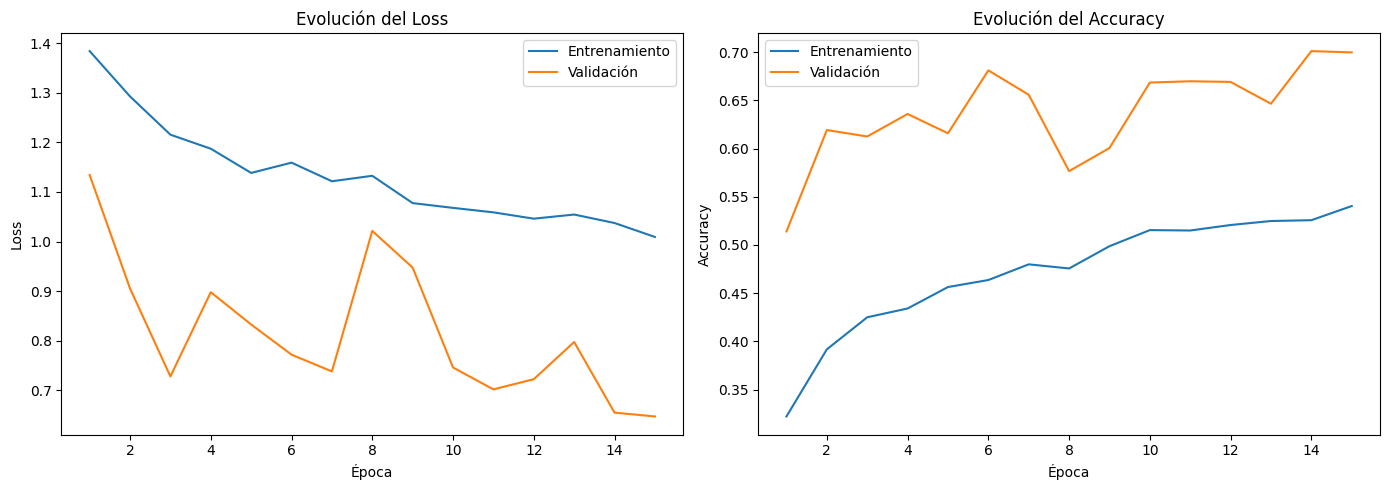

In [ ]:
def plot_training_curves(history):
    epochs = range(1, len(history["train_loss"]) + 1)

    plt.figure(figsize=(14, 5))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["train_loss"], label="Entrenamiento")
    plt.plot(epochs, history["val_loss"], label="Validación")
    plt.title("Evolución del Loss")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["train_acc"], label="Entrenamiento")
    plt.plot(epochs, history["val_acc"], label="Validación")
    plt.title("Evolución del Accuracy")
    plt.xlabel("Época")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_training_curves(history)


# PARTE 6: Evaluación del modelo

In [ ]:
def evaluate_model(model, test_loader, device, class_names):
    model.eval()
    y_true = []
    y_pred = []
    y_probs = []

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
            y_probs.extend(probs.cpu().numpy())

    return np.array(y_true), np.array(y_pred), np.array(y_probs)

# Ejecutar evaluación
y_true, y_pred, y_probs = evaluate_model(model, test_loader, device, le.classes_)

🔍 Classification Report
                       precision    recall  f1-score   support

carcinoma basocelular       0.42      0.48      0.45        77
       dermatofibroma       0.00      0.00      0.00        17
       lesión benigna       0.45      0.39      0.42       165
      lesión vascular       0.33      0.64      0.43        22
             melanoma       0.35      0.57      0.44       167
                nevus       0.87      0.79      0.83      1006
  queratosis actínica       0.38      0.24      0.30        49

             accuracy                           0.68      1503
            macro avg       0.40      0.45      0.41      1503
         weighted avg       0.71      0.68      0.69      1503



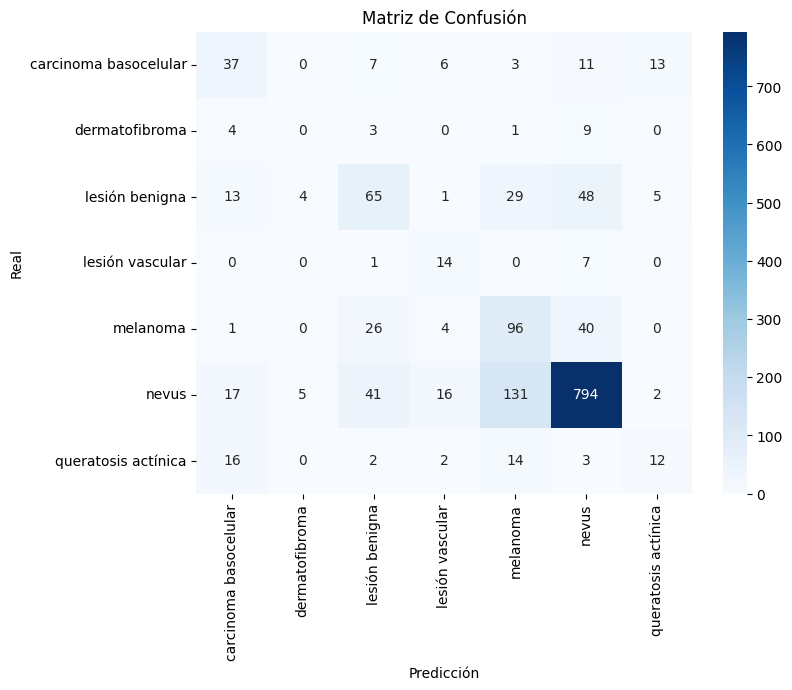

In [ ]:
# Reporte por clase
print("🔍 Classification Report")
print(classification_report(y_true, y_pred, target_names=le.classes_))

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()


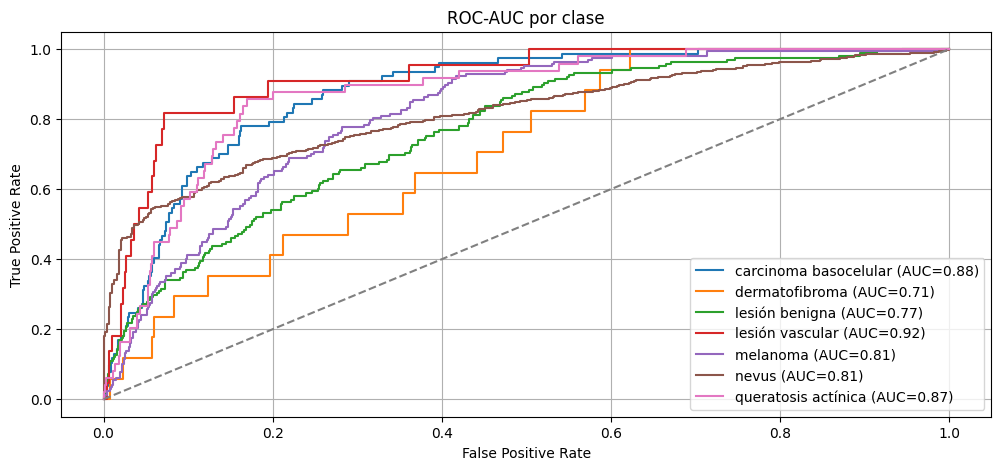

In [ ]:
# ROC-AUC y PR-AUC por clase (one-vs-rest)
n_classes = len(le.classes_)
y_true_onehot = np.eye(n_classes)[y_true]

# ROC-AUC
plt.figure(figsize=(12, 5))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_onehot[:, i], y_probs[:, i])
    auc = roc_auc_score(y_true_onehot[:, i], y_probs[:, i])
    plt.plot(fpr, tpr, label=f"{le.classes_[i]} (AUC={auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC por clase")
plt.legend()
plt.grid(True)
plt.show()


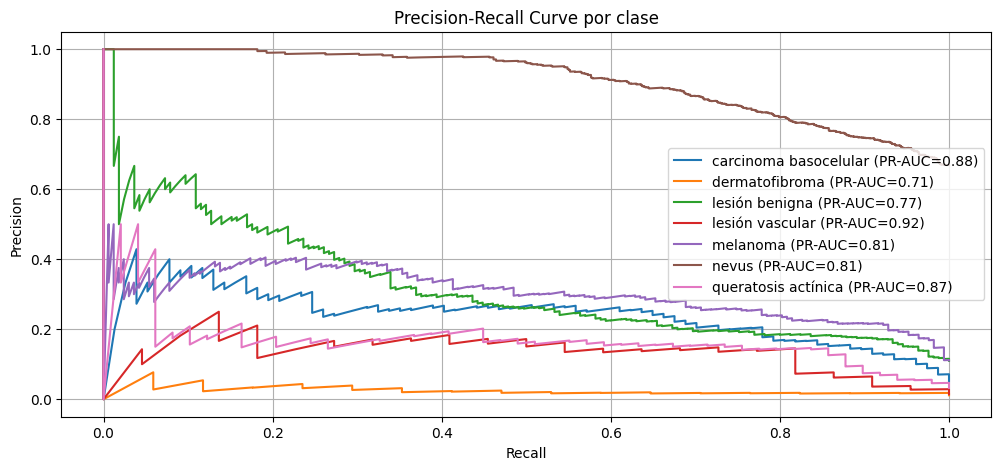

In [ ]:
# PR-AUC
plt.figure(figsize=(12, 5))

for i in range(n_classes):
    precision, recall, _ = precision_recall_curve(y_true_onehot[:, i], y_probs[:, i])
    pr_auc = roc_auc_score(y_true_onehot[:, i], y_probs[:, i])  # en este caso AUC-PR ~ AUC-ROC
    plt.plot(recall, precision, label=f"{le.classes_[i]} (PR-AUC={pr_auc:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve por clase")
plt.legend()
plt.grid(True)
plt.show()


# PARTE 7: Visualización de interpretabilidad con Grad-CAM

Objetivo:
Aplicar Grad-CAM sobre imágenes del conjunto de validación o prueba. Visualizar:


*   Imagen original.
*   Mapa de calor (*heatmap*) Grad-CAM.
*   Superposición del Grad-CAM sobre la imagen

Con esto será posible visualizar claramente qué partes de la imagen fueron relevantes para la predicción. Así se puede detectar si el modelo se enfoca en regiones relevantes o irrelevantes.

Esto mejora la interpretabilidad en aplicaciones médicas como el cáncer de piel.

In [ ]:
def generate_gradcam_heatmap(model, image_tensor, target_class=None, last_conv_layer_name='conv3'):
    model.eval()

    # Hook para capturar la salida de la última capa convolucional
    activations = []
    gradients = []

    def forward_hook(module, input, output):
        activations.append(output.detach())

    def backward_hook(module, grad_in, grad_out):
        gradients.append(grad_out[0].detach())

    # Buscar la capa convolucional por nombre
    for name, module in model.named_modules():
        if name == last_conv_layer_name:
            module.register_forward_hook(forward_hook)
            module.register_backward_hook(backward_hook)
            break

    # Forward
    output = model(image_tensor)
    if target_class is None:
        target_class = output.argmax(dim=1).item()

    # Backward
    model.zero_grad()
    class_score = output[:, target_class]
    class_score.backward()

    # Obtener activaciones y gradientes
    acts = activations[0][0]         # shape: [C, H, W]
    grads = gradients[0][0]          # shape: [C, H, W]

    # Calcular importancia de cada canal
    weights = grads.mean(dim=(1, 2)) # promedio espacial por canal
    cam = torch.zeros_like(acts[0])
    for i, w in enumerate(weights):
        cam += w * acts[i]

    # ReLU y normalización
    cam = F.relu(cam)
    cam -= cam.min()
    cam /= cam.max()
    return cam.cpu().numpy()





def show_gradcam(model, dataset, idx, last_conv_layer='conv3'):
    # Cargar una muestra del conjunto
    image_tensor, label = dataset[idx]
    input_tensor = image_tensor.unsqueeze(0).to(device)

    # Obtener mapa de calor
    heatmap = generate_gradcam_heatmap(model, input_tensor, last_conv_layer_name=last_conv_layer)

    # Convertir imagen a formato visualizable (RGB, uint8)
    img_np = image_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np * 0.5 + 0.5)  # desnormalizar
    img_np = np.clip(img_np * 255, 0, 255).astype(np.uint8)

    # Resize heatmap
    heatmap_resized = cv2.resize(heatmap, (img_np.shape[1], img_np.shape[0]))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    # Superponer heatmap sobre imagen original
    superimposed = cv2.addWeighted(img_np, 0.6, heatmap_colored, 0.4, 0)

    # Mostrar
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 3, 1)
    plt.imshow(img_np)
    plt.title("Imagen original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(heatmap_resized, cmap='jet')
    plt.title("Grad-CAM Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(superimposed)
    plt.title("Superposición")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Mostrar etiquetas
    predicted_class = model(input_tensor).argmax(dim=1).item()
    print(f"🔍 Verdadero: {le.classes_[label]} | 🔮 Predicho: {le.classes_[predicted_class]}")



/usr/local/lib/python3.11/dist-packages/torch/nn/modules/module.py:1830: FutureWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  self._maybe_warn_non_full_backward_hook(args, result, grad_fn)


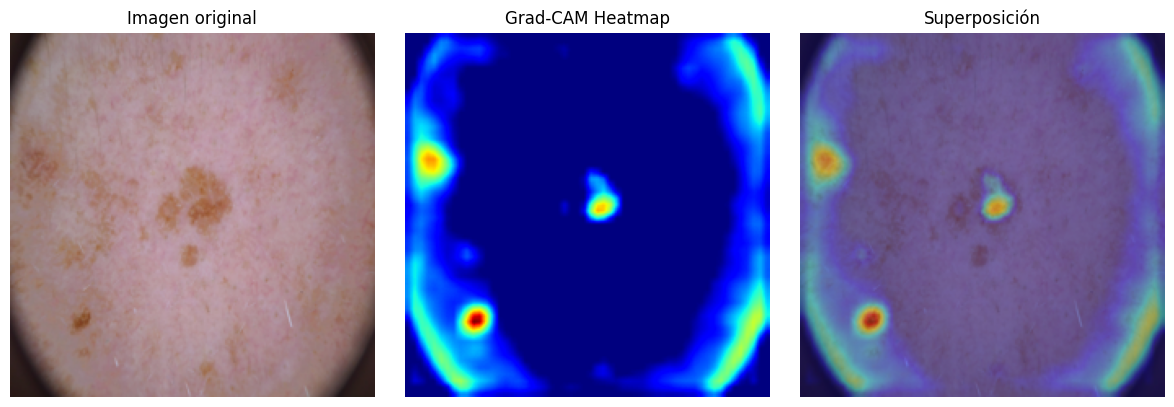

🔍 Verdadero: lesión benigna | 🔮 Predicho: lesión benigna


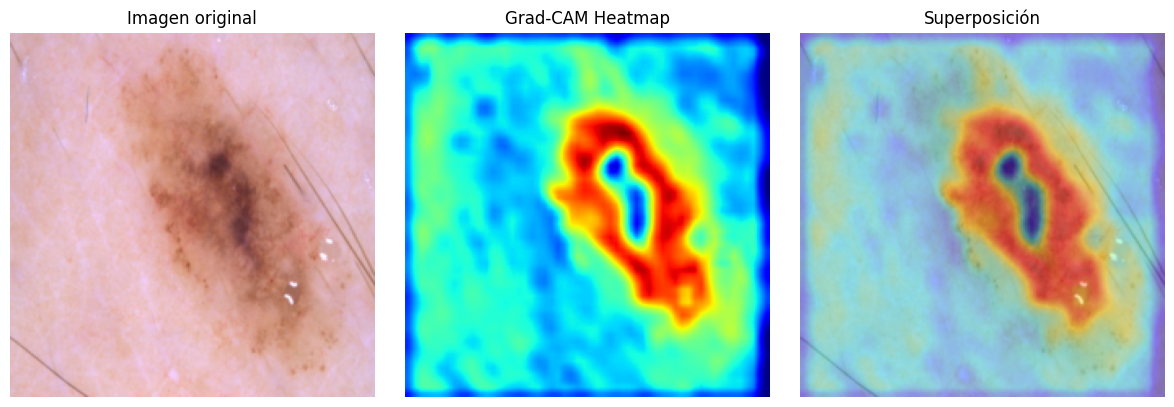

🔍 Verdadero: nevus | 🔮 Predicho: queratosis actínica


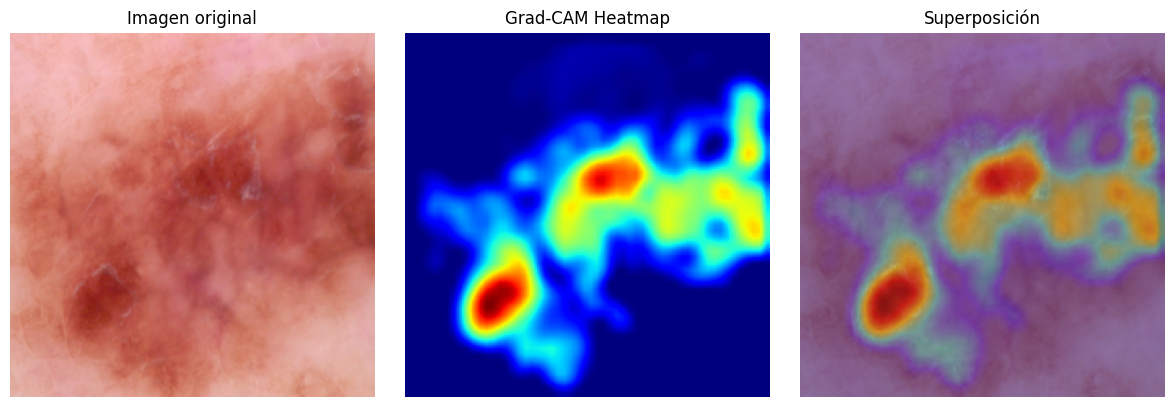

🔍 Verdadero: melanoma | 🔮 Predicho: nevus


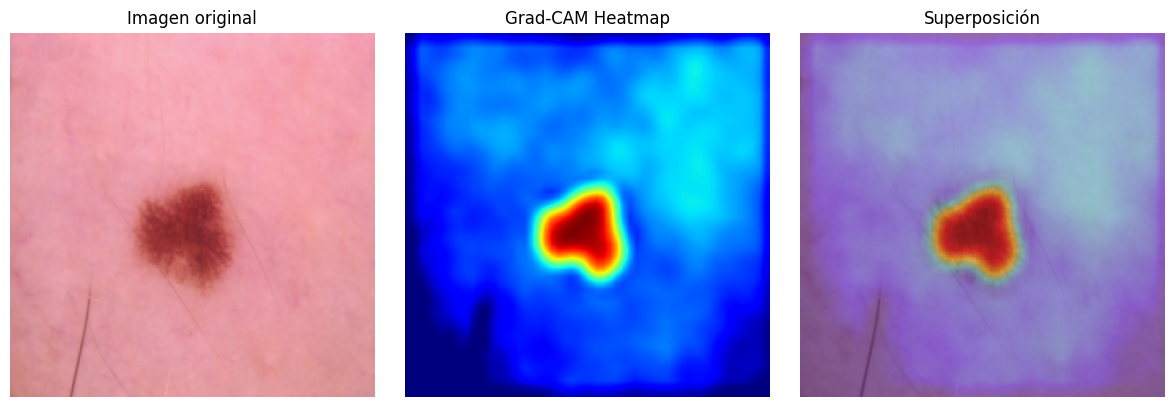

🔍 Verdadero: nevus | 🔮 Predicho: nevus


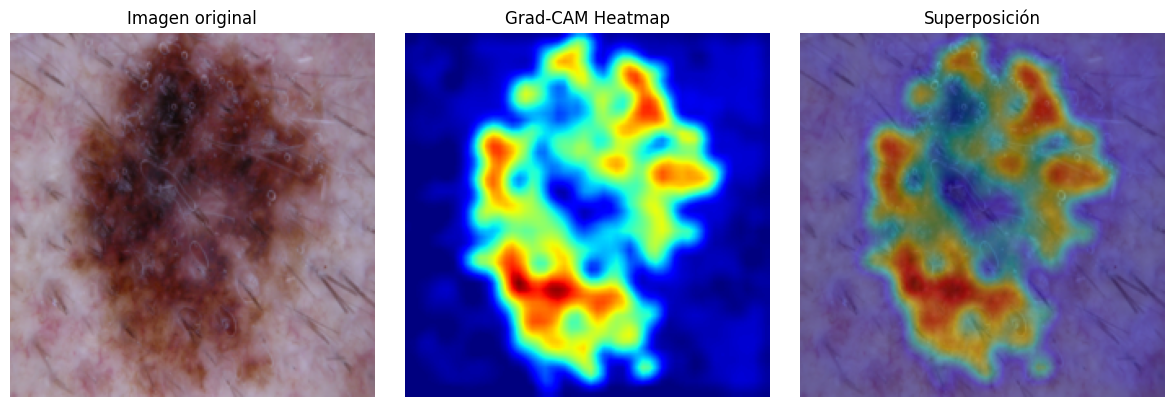

🔍 Verdadero: melanoma | 🔮 Predicho: melanoma


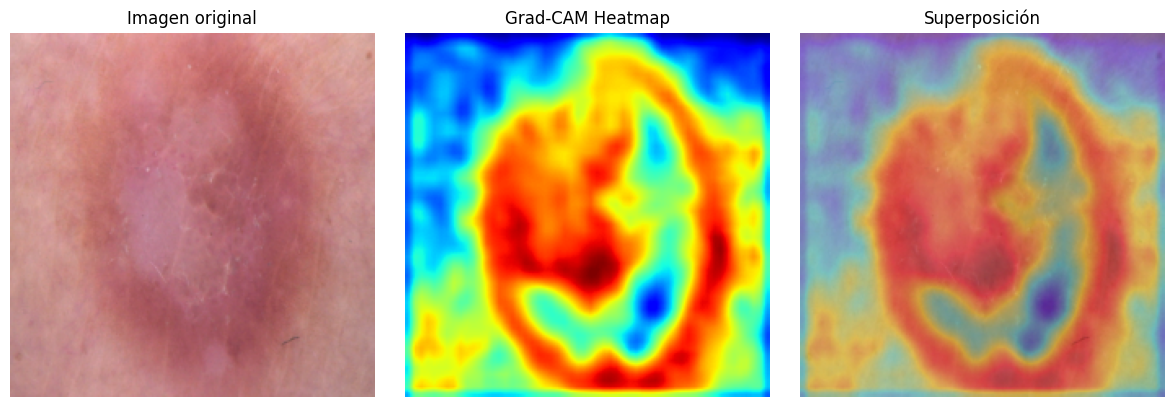

🔍 Verdadero: dermatofibroma | 🔮 Predicho: queratosis actínica


In [ ]:
# Mostrar Grad-CAM para 6 imágenes aleatorias del conjunto de validación

indices = random.sample(range(len(val_dataset)), 6)
for idx in indices:
    show_gradcam(model, val_dataset, idx)


**Primer modificación:**
*Variación de color:*

transforms.ColorJitter(brightness=0.1, contrast=0.1), #

Resultado: Parece no haber mejorado casi nada el Accuracy ni la matriz de confusión.

**Segunda modificación:**
*Aumento de número de épocas de 5 a 9.*

Resultado: Se observa una ligera mejora en la evolución del Loss y los resultados en la matriz de confusión también mejoraron levemente casi para todas las clases a excepción de "Carcinoma Basocelular". También se observa una mejora en promedio para el Recall y el F1-Score de las clases.

**Cuarta Modificación:**
*Añadido de un cuarto bloque convolucional aumentando los filtros a 256.*

Resultado: Se sigue observando la mejora en la evolución del Loss y en los resultados en la matriz de confusión  casi para todas las clases a excepción de "Carcinoma Basocelular". Pero hay algo de "ruido" o variación en la gráfica del accuracy, esto quizás es causado por la primera modificación hecha que fue la transformación en el color.
Removeremos esa transformación para ver los resultados.

**Quinta Modificación:**
*Remoción de la transformación en el color.*

Resultado: En general se observan los mismos resultados y las gráficas se ven casi igual.

**Sexta Modificación**
*Programador de Tasa de Aprendizaje.*

Se implementó:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
Dentro del loop de épocas (después de la validación):
scheduler.step(val_epoch_loss)

Resultado:
Se observó una mejora en casi todas las clases en la matriz de confusión a excepción de "Carcinoma Basocelular", También se observa una mejora en promedio para el Recall y el F1-Score, haremos una prueba más aumentando el número de épocas para ver si eso ayuda a la convergencia del modelo.

**Séptima Modificación**
*Aumentar el número de épocas a 15.*
Se observó una mejora en casi todas las clases en la matriz de confusión a excepción de "Carcinoma Basocelular", hubo también una mejora en la detección de Nevus sin afectar a Mleanoma.
El clasification report es el siguiente:

                        precision    recall  f1-score
    
    carcinoma basocelular       0.29      0.30      0.29
       dermatofibroma       0.07      0.53      0.13
       lesión benigna       0.36      0.43      0.39
      lesión vascular       0.27      0.82      0.40
             melanoma       0.34      0.50      0.41
                nevus       0.93      0.66      0.77
    queratosis actínica       0.29      0.47      0.36

**Octava Modificación**
*Introducción de un Sampler*

Agregamos un muestreador de clases para que cada vez que son escogidas las imágenes en los batches de entrenamiento el modelo vea aproximadamente la misma cantidad de cada clase en cada paso, y así, aprenda también a reconocer las clases que tienen menos instancias. Esto se hizo añadiendo lo siguiente:

sample_weights = [class_weights[label] for label in train_labels]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

Y en el train_loader:

train_loader = DataLoader(train_dataset, batch_size=32, sampler=sampler)

Resultado:
Se observó una mejora considerable para las clases minoritarias en su recall, por ejemplo, con la clase Lesión Vascular el recall fue perfecto, sin embargo, el nevus por ejemplo se vió muy afectado.
Lo que está ocurriendo es un efecto secundario clásico del sobremuestreo extremo: el modelo ha desarrollado un sesgo masivo hacia el dermatofibroma y hacia lesión vascular.

Este es el clasification report:

                        precision    recall  f1-score   
                      
    carcinoma basocelular       0.20      0.35      0.25    
       dermatofibroma       0.04      0.76      0.07       
       lesión benigna       0.33      0.23      0.27      
      lesión vascular       0.12      1.00      0.22        
             melanoma       0.28      0.58      0.38    
                nevus       0.99      0.26      0.41
    queratosis actínica       0.18      0.45      0.26    

**Novena Modificación**
*Suavizar los pesos.*

El peso calculado por compute_class_weight es muy agresivo. Entonces reducimos la disparidad usando la raíz cuadrada de las estos. Esto reduce la "obsesión" del modelo con las clases minoritarias.

Resultado:
Se vió una mejora significativa casi en todas las clases.

Este es el clasification report:

                        precision    recall  f1-score
    carcinoma basocelular       0.29      0.58      0.38       
       dermatofibroma       0.00      0.00      0.00      
       lesión benigna       0.40      0.43      0.42     
      lesión vascular       0.35      0.86      0.50      
             melanoma       0.40      0.57      0.47     
                nevus       0.92      0.73      0.82     
    queratosis actínica       0.34      0.47      0.39     

**Décima Modificación**
*Incrementar el peso para la clase Melanoma específicamente.*

Se aumentó el peso al doble para castigar errores del modelo con la clase Melanoma de este manera:

class_weights[4] *= 2

Se hizo esto debido a que es una de las clases que más nos interesa mejorar sus métricas por la importancia que tiene en términos de medicina.
Resultado:
Al parecer no hubo mejoría más que en carcinoma basocelular, lesión benigna y nevus.
Se obtuvo el siguiente clasification report:

                        precision    recall  f1-score
    carcinoma basocelular       0.42      0.48      0.45
       dermatofibroma       0.00      0.00      0.00
       lesión benigna       0.45      0.39      0.42
      lesión vascular       0.33      0.64      0.43
             melanoma       0.35      0.57      0.44
                nevus       0.87      0.79      0.83
    queratosis actínica       0.38      0.24      0.30


# Análisis final del entrenamiento y desempeño del modelo
🔹 **1. Evolución del entrenamiento**

La curva de pérdida (*loss*) muestra una tendencia descendente tanto en entrenamiento como en validación, lo cual es una buena señal: el modelo está aprendiendo y no hay señales claras de sobreajuste (*overfitting*) aún.

La precisión (*accuracy*) en validación supera a la de entrenamiento en todas las épocas. Esto puede indicar:

Un modelo regularizado que aún no ha convergido completamente.

Que el conjunto de validación es algo más sencillo que el de entrenamiento (posible por muestreo estratificado).

Conclusión: el modelo mejora de forma consistente; es probable que con más épocas y ajustes, su rendimiento continúe creciendo.


🔹 **2. Desempeño en el conjunto de prueba**

El *accuracy* solo no es suficiente en *datasets* desbalanceados como HAM10000.


Observaciones clave:

El modelo logra detectar correctamente melanoma con un *recall* de 57 %, lo cual es clínicamente relevante.

Se logró una alta precisión en nevus (0.92), y con *recall* relativamente alto (0.73): predice nevus con confianza, y  detecta suficientes, se puede observar esta mejora en la matriz de confusión.

Clases minoritarias como vasc, df, akiec tienen bajo rendimiento, lo cual es esperado por el desbalance.

El promedio macro (sin ponderar) aunque mejoró sobre lo original es bajo aun: precision = 0.4, recall = 0.44, F1 = 0.41, lo que refleja ese desbalance.

El promedio ponderado (weighted avg) mejora gracias al dominio de la clase nevus.


🔹 **3. Interpretabilidad (Grad-CAM)**

Grad-CAM mostró activaciones razonables centradas en las regiones afectadas de la piel.

El modelo reacciona a regiones relevantes de las imágenes, lo que confirma que su atención no es aleatoria.

Sin embargo, su capacidad de decisión aún no es suficientemente discriminativa en clases minoritarias, como son los casos críticos como el melanoma, especialmente en escenarios con estructuras complejas o patrones visuales atípicos.

Esto refuerza la necesidad de:

* Ampliar el número de muestras de clases minoritarias.

* Utilizar arquitecturas más profundas o modelos preentrenados.

* Aplicar técnicas de balanceo y ajustes de pérdida más agresivos.


🏁 **Conclusión general**

El modelo ha logrado aprender patrones clínicamente útiles (especialmente en clases como melanoma y nevus), pero todavía requiere trabajo para generalizar correctamente en clases poco representadas. A pesar del desbalance, se alcanzó un desempeño razonable, y el uso de *class weights*, regularización y Grad-CAM fortaleció la explicación y solidez del experimento.